In [595]:
import pandas as pd
import numpy as np

print("Notebook is working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Notebook is working!
Pandas version: 3.0.6
NumPy version: 2.5.4


In [596]:
import pandas as pd

df = pd.read_csv("../data/raw/ecommerce_sales_raw.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

Dataset loaded successfully!
Rows and columns: (1000, 16)


In [597]:
display(df.head())

,order_id,order_date,customer_id,customer_segment,city,category,product,quantity,unit_price,discount_percent,sales,cost,profit,payment_method,order_status,shipping_days
0,ORD00001,2025-11-24,CUST0045,Returning,Pune,Electronics,Wireless Mouse,3,18.99,0.0,56.97,28.5,28.47,UPI,Delivered,2.0
1,ORD00002,2025-02-17,CUST0113,Returning,Delhi,Home & Kitchen,Coffee Maker,2,79.99,0.0,159.98,96.0,63.98,UPI,Delivered,7.0
2,ORD00003,2025-03-23,CUST0048,Returning,Chennai,Books,Python for Beginners,1,27.99,0.0,27.99,11.0,16.99,Debit Card,Delivered,2.0
3,ORD00004,2025-11-06,CUST0151,Loyal,Kochi,Clothing,Cotton T-Shirt,3,19.99,5.0,56.97,24.0,32.97,Debit Card,Delivered,2.0
4,ORD00005,2025-10-23,CUST0120,Loyal,Jaipur,Home & Kitchen,Water Bottle,1,16.99,0.0,16.99,7.0,9.99,Debit Card,Delivered,2.0


In [598]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          1000 non-null   str    
 1   order_date        1000 non-null   str    
 2   customer_id       1000 non-null   str    
 3   customer_segment  1000 non-null   str    
 4   city              1000 non-null   str    
 5   category          1000 non-null   str    
 6   product           1000 non-null   str    
 7   quantity          1000 non-null   int64  
 8   unit_price        1000 non-null   float64
 9   discount_percent  1000 non-null   float64
 10  sales             1000 non-null   float64
 11  cost              1000 non-null   float64
 12  profit            1000 non-null   float64
 13  payment_method    1000 non-null   str    
 14  order_status      1000 non-null   str    
 15  shipping_days     836 non-null    float64
dtypes: float64(6), int64(1), str(9)
memory usage: 125.1 KB

In [599]:
df.isnull().sum()

order_id              0
order_date            0
customer_id           0
customer_segment      0
city                  0
category              0
product               0
quantity              0
unit_price            0
discount_percent      0
sales                 0
cost                  0
profit                0
payment_method        0
order_status          0
shipping_days       164
dtype: int64

In [600]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

Duplicate rows: 0
Duplicate order IDs: 0


In [601]:
df["order_status"].value_counts()

order_status
Delivered    679
Cancelled    164
Returned     157
Name: count, dtype: int64

In [602]:
df[["quantity", "unit_price", "sales", "cost", "profit"]].describe()

,quantity,unit_price,sales,cost,profit
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,1.989000,35.176300,65.699020,35.949500,29.749520
std,1.112707,22.578975,60.372858,39.029902,23.004623
min,1.000000,9.990000,7.990000,3.500000,4.490000
25%,1.000000,16.990000,25.400000,11.000000,13.740000
50%,2.000000,27.990000,44.990000,22.500000,21.985000
75%,3.000000,49.990000,81.742500,46.000000,39.480000
max,5.000000,89.990000,427.450000,275.000000,152.450000


In [603]:
print("Quantity <= 0:", (df["quantity"] <= 0).sum())
print("Unit price <= 0:", (df["unit_price"] <= 0).sum())
print("Sales < 0:", (df["sales"] < 0).sum())
print("Cost < 0:", (df["cost"] < 0).sum())

Quantity <= 0: 0
Unit price <= 0: 0
Sales < 0: 0
Cost < 0: 0


In [604]:
check = df["sales"] - df["cost"]

print("Rows where profit calculation differs:", (df["profit"].round(2) != check.round(2)).sum())

Rows where profit calculation differs: 0


In [605]:
df.isnull().sum()

order_id              0
order_date            0
customer_id           0
customer_segment      0
city                  0
category              0
product               0
quantity              0
unit_price            0
discount_percent      0
sales                 0
cost                  0
profit                0
payment_method        0
order_status          0
shipping_days       164
dtype: int64

In [606]:
print("Missing shipping days by order status:")
print(df.groupby("order_status")["shipping_days"].apply(lambda x: x.isnull().sum()))

Missing shipping days by order status:
order_status
Cancelled    164
Delivered      0
Returned       0
Name: shipping_days, dtype: int64


In [607]:
clean = df.copy()

print("Original rows:", len(df))
print("Cleaned copy rows:", len(clean))
print("Missing shipping days:", clean["shipping_days"].isnull().sum())

Original rows: 1000
Cleaned copy rows: 1000
Missing shipping days: 164


In [608]:
clean.to_csv("../data/processed/ecommerce_sales.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [609]:
check = pd.read_csv("../data/processed/ecommerce_sales.csv")

print("Saved dataset shape:", check.shape)
print("Missing values:", check.isnull().sum().sum())

Saved dataset shape: (1000, 16)
Missing values: 164


In [610]:
print("Order status counts:")
print(check["order_status"].value_counts())

print("\nTotal orders:", len(check))
print("Unique order IDs:", check["order_id"].nunique())

Order status counts:
order_status
Delivered    679
Cancelled    164
Returned     157
Name: count, dtype: int64

Total orders: 1000
Unique order IDs: 1000


In [611]:
total_sales = check["sales"].sum()
total_profit = check["profit"].sum()
total_orders = check["order_id"].nunique()
avg_order_value = total_sales / total_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: ${avg_order_value:,.2f}")

Total Sales: $65,699.02
Total Profit: $29,749.52
Total Orders: 1,000
Average Order Value: $65.70


In [612]:
status_summary = check.groupby("order_status").agg(
    orders=("order_id", "nunique"),
    sales=("sales", "sum"),
    profit=("profit", "sum")
).round(2)

display(status_summary)

,orders,sales,profit
order_status,,,
Cancelled,164,10711.48,4790.73
Delivered,679,43487.53,19796.78
Returned,157,11500.01,5162.01


In [613]:
category_sales = check.groupby("category").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique")
).sort_values("sales", ascending=False).round(2)

display(category_sales)

,sales,profit,orders
category,,,
Clothing,16262.12,7407.12,192
Home & Kitchen,14850.94,5978.94,192
Sports,12721.87,5721.37,225
Electronics,11851.42,4864.42,172
Books,10012.67,5777.67,219


In [614]:
city_sales = check.groupby("city").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique")
).sort_values("sales", ascending=False).round(2)

display(city_sales)

,sales,profit,orders
city,,,
Ahmedabad,7793.18,3421.68,94
Jaipur,7562.96,3409.21,118
Mumbai,6853.55,3061.55,111
Delhi,6840.58,3187.83,106
Hyderabad,6623.50,2886.50,95
Kolkata,6605.01,2997.01,102
Chennai,6199.53,2775.53,88
Kochi,6070.96,2797.46,94
Pune,5746.38,2681.63,92


In [615]:
check["order_date"] = pd.to_datetime(check["order_date"])

monthly_sales = check.groupby(
    check["order_date"].dt.to_period("M")
).agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "nunique")
).round(2)

monthly_sales.index = monthly_sales.index.astype(str)

display(monthly_sales)

,sales,profit,orders
order_date,,,
2025-01,6510.40,2926.65,94
2025-02,4389.49,2063.74,73
2025-03,5753.26,2529.26,88
2025-04,4659.40,2128.90,73
2025-05,4859.53,2166.03,78
2025-06,5108.35,2360.35,71
2025-07,5456.13,2436.63,83
2025-08,5248.43,2467.68,81
2025-09,6482.75,2822.75,84


In [616]:
customer_summary = check.groupby("customer_segment").agg(
    orders=("order_id", "nunique"),
    sales=("sales", "sum"),
    profit=("profit", "sum"),
    customers=("customer_id", "nunique")
).sort_values("sales", ascending=False).round(2)

display(customer_summary)

,orders,sales,profit,customers
customer_segment,,,,
Returning,391,25419.37,11436.37,207
New,351,21961.78,10097.28,185
Loyal,258,18317.87,8215.87,162


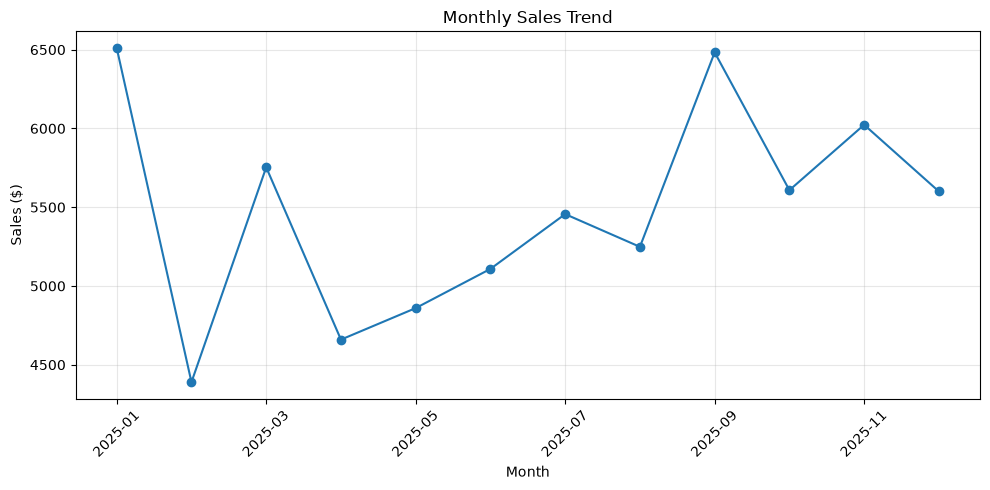

In [617]:
import matplotlib.pyplot as plt

monthly_sales["sales"].plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

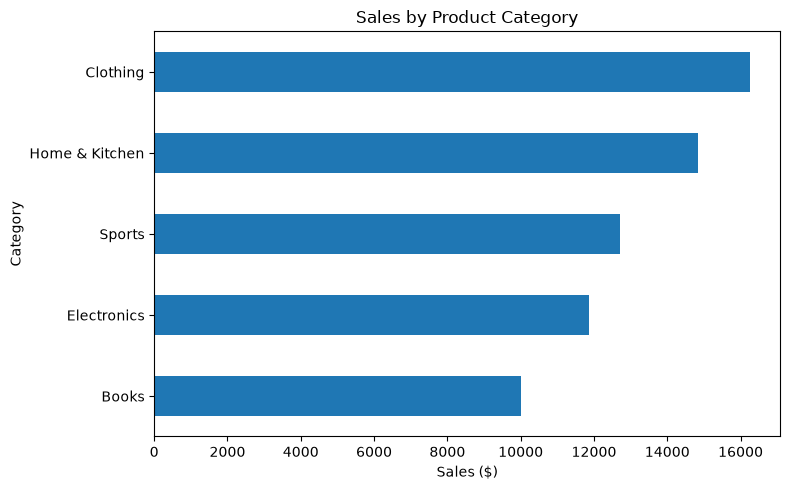

In [618]:
category_sales["sales"].sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Sales by Product Category")
plt.xlabel("Sales ($)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [619]:
category_sales.to_csv("../data/processed/category_sales.csv")
print("Category analysis exported!")

Category analysis exported!


In [620]:
city_sales.to_csv("../data/processed/city_sales.csv")
print("City analysis exported!")

City analysis exported!


In [621]:
monthly_sales.to_csv("../data/processed/monthly_sales.csv")
print("Monthly analysis exported!")

Monthly analysis exported!


In [622]:
customer_summary.to_csv("../data/processed/customer_summary.csv")
print("Customer analysis exported!")

Customer analysis exported!


In [623]:
status_summary.to_csv("../data/processed/status_summary.csv")
print("Order status analysis exported!")

Order status analysis exported!


In [624]:
print("PROJECT DATA ANALYSIS SUMMARY")
print("-----------------------------")
print("Total rows:", check.shape[0])
print("Total columns:", check.shape[1])
print("Unique orders:", check["order_id"].nunique())
print("Total sales:", round(check["sales"].sum(), 2))
print("Total profit:", round(check["profit"].sum(), 2))
print("Categories:", check["category"].nunique())
print("Cities:", check["city"].nunique())
print("Customer segments:", check["customer_segment"].nunique())
print("Order statuses:", check["order_status"].nunique())

PROJECT DATA ANALYSIS SUMMARY
-----------------------------
Total rows: 1000
Total columns: 16
Unique orders: 1000
Total sales: 65699.02
Total profit: 29749.52
Categories: 5
Cities: 10
Customer segments: 3
Order statuses: 3


In [625]:
import os

folder = "../data/processed"

for file in os.listdir(folder):
    print(file)

category_sales.csv
city_sales.csv
customer_summary.csv
ecommerce_sales.csv
monthly_sales.csv
status_summary.csv


In [626]:
import os

folder = "../data/processed"

for file in os.listdir(folder):
    if file.endswith(".csv"):
        temp = pd.read_csv(os.path.join(folder, file))
        print(f"{file}: {temp.shape[0]} rows, {temp.shape[1]} columns")

category_sales.csv: 5 rows, 4 columns
city_sales.csv: 10 rows, 4 columns
customer_summary.csv: 3 rows, 5 columns
ecommerce_sales.csv: 1000 rows, 16 columns
monthly_sales.csv: 12 rows, 4 columns
status_summary.csv: 3 rows, 4 columns


In [627]:
import sqlite3

conn = sqlite3.connect("../database/ecommerce.db")

result = pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM ecommerce_sales",
    conn
)

display(result)

conn.close()

,total_rows
0,1000


In [628]:
conn = sqlite3.connect("../database/ecommerce.db")

preview = pd.read_sql_query(
    "SELECT * FROM ecommerce_sales LIMIT 5",
    conn
)

display(preview)

conn.close()

,order_id,order_date,customer_id,customer_segment,city,category,product,quantity,unit_price,discount_percent,sales,cost,profit,payment_method,order_status,shipping_days
0,ORD00001,2025-11-24,CUST0045,Returning,Pune,Electronics,Wireless Mouse,3,18.99,0.0,56.97,28.5,28.47,UPI,Delivered,2.0
1,ORD00002,2025-02-17,CUST0113,Returning,Delhi,Home & Kitchen,Coffee Maker,2,79.99,0.0,159.98,96.0,63.98,UPI,Delivered,7.0
2,ORD00003,2025-03-23,CUST0048,Returning,Chennai,Books,Python for Beginners,1,27.99,0.0,27.99,11.0,16.99,Debit Card,Delivered,2.0
3,ORD00004,2025-11-06,CUST0151,Loyal,Kochi,Clothing,Cotton T-Shirt,3,19.99,5.0,56.97,24.0,32.97,Debit Card,Delivered,2.0
4,ORD00005,2025-10-23,CUST0120,Loyal,Jaipur,Home & Kitchen,Water Bottle,1,16.99,0.0,16.99,7.0,9.99,Debit Card,Delivered,2.0
